# MAL Anime: catalog, scores, and audience

A cross-sectional analysis of the acquired MyAnimeList catalog, grouped by release metadata and current MAL engagement.

**Interpretation:** MAL scores, ranks, and popularity are snapshots from extraction, not historical measurements. Genre and studio credits are many-to-many. Group comparisons use minimum sample thresholds; weighted scores use anime mean scores weighted by scoring-user counts and are estimates, not raw-vote aggregates.

In [8]:
from pathlib import Path
import importlib
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

project_root = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
sys.path.insert(0, str(project_root))

from analysis import queries
queries = importlib.reload(queries)
from load_sql.sql_loader import get_engine

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 120, 'axes.titleweight': 'bold'})
engine = get_engine()

overview = queries.dataset_overview(engine).iloc[0]
df_year = queries.catalog_by_year(engine)
df_season = queries.seasonal_catalog(engine)
df_formats = queries.media_type_score_profile(engine, min_count=30)
df_genres = queries.genre_score_profile(engine, min_count=100)
df_studio_year = queries.studio_output_by_year(engine)
df_studios = queries.studio_score_profile(engine, min_count=30)
df_sources = queries.source_score_profile(engine, min_count=100)
df_ratings = queries.rating_score_profile(engine, min_count=30)
df_episodes = queries.episode_band_score_profile(engine, min_count=30)
df_audience = queries.audience_score_sample(engine, limit=5000)
df_top = queries.top_ranked_anime(engine, min_scoring_users=1000, limit=25)

coverage = pd.DataFrame({
    'Metric': ['Anime records', 'Scored anime', 'Release year known', 'Episode count known', 'Audience count known'],
    'Count': [overview['anime_count'], overview['scored_count'], overview['dated_count'], overview['episode_count'], overview['audience_count']],
})
coverage['Coverage'] = coverage['Count'] / overview['anime_count']
display(coverage.style.format({'Count': '{:,.0f}', 'Coverage': '{:.1%}'}).hide(axis='index'))
print(f"Mean MAL score: {overview['mean_score']:.2f} | Median: {overview['median_score']:.2f} | Release years: {int(overview['first_release_year'])}-{int(overview['last_release_year'])}")

Metric,Count,Coverage
Anime records,"27,503",100.0%
Scored anime,"19,352",70.4%
Release year known,"22,952",83.5%
Episode count known,"27,503",100.0%
Audience count known,"27,503",100.0%


Mean MAL score: 6.39 | Median: 6.37 | Release years: 1917-2027


## Catalog rhythm

Release volume shows how the catalog and formats changed over time; the seasonal heatmap highlights the annual cadence. Years with incomplete MAL dates are excluded from these views.

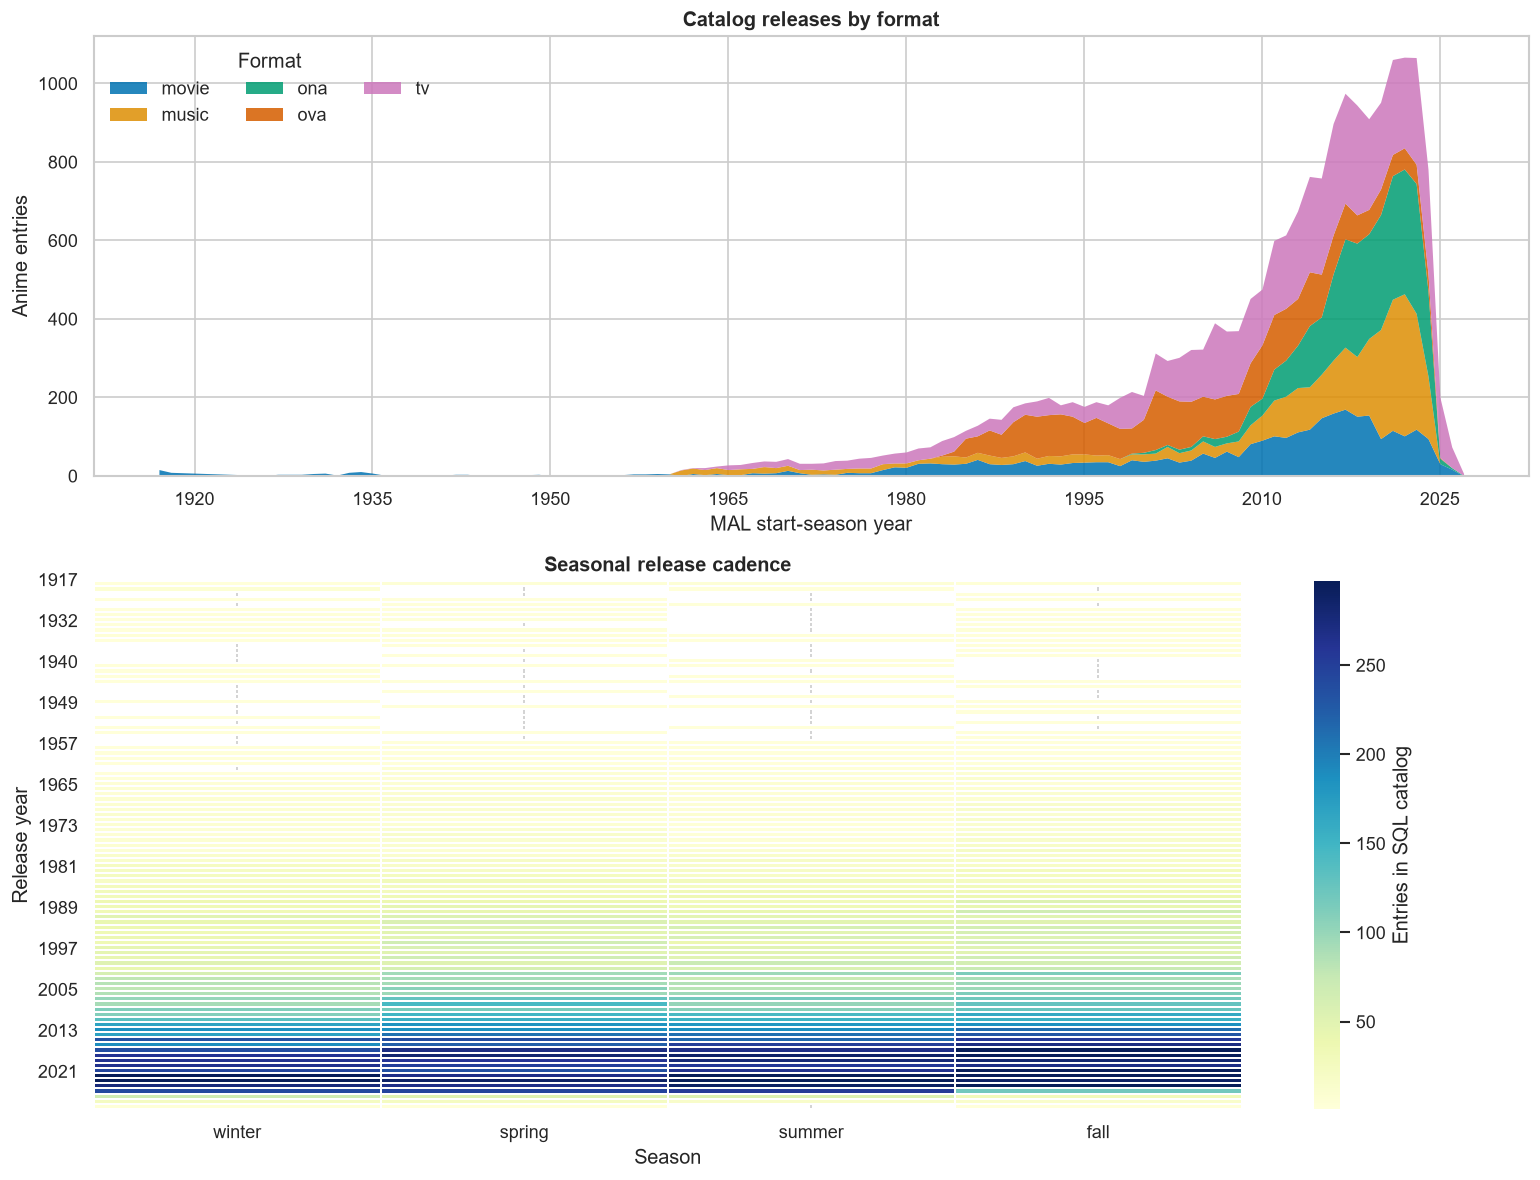

In [9]:
type_totals = df_year.groupby('media_type', dropna=True)['anime_count'].sum().sort_values(ascending=False)
top_types = type_totals.head(5).index
annual = (
    df_year[df_year['media_type'].isin(top_types)]
    .pivot(index='year', columns='media_type', values='anime_count')
    .fillna(0)
    .sort_index()
)
season_order = ['winter', 'spring', 'summer', 'fall']
season_heat = df_season.pivot(index='year', columns='season', values='anime_count').reindex(columns=season_order)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 10), gridspec_kw={'height_ratios': [1, 1.2]})
annual.plot.area(ax=ax1, alpha=0.86, linewidth=0)
ax1.set(title='Catalog releases by format', xlabel='MAL start-season year', ylabel='Anime entries')
ax1.legend(title='Format', ncol=3, frameon=False, loc='upper left')
ax1.xaxis.set_major_locator(plt.MaxNLocator(12))

sns.heatmap(season_heat, cmap='YlGnBu', robust=True, linewidths=0.15, linecolor='white', ax=ax2,
            cbar_kws={'label': 'Entries in SQL catalog'})
ax2.set(title='Seasonal release cadence', xlabel='Season', ylabel='Release year')
ax2.set_yticks(range(0, len(season_heat.index), max(1, len(season_heat.index) // 12)))
ax2.set_yticklabels(season_heat.index[::max(1, len(season_heat.index) // 12)], rotation=0)
fig.tight_layout()
plt.show()

## Scores and catalog categories

Scores are MAL means, not raw voter-level data. The comparisons show medians and interquartile ranges where possible, with minimum scored-anime thresholds to avoid ranking tiny groups.

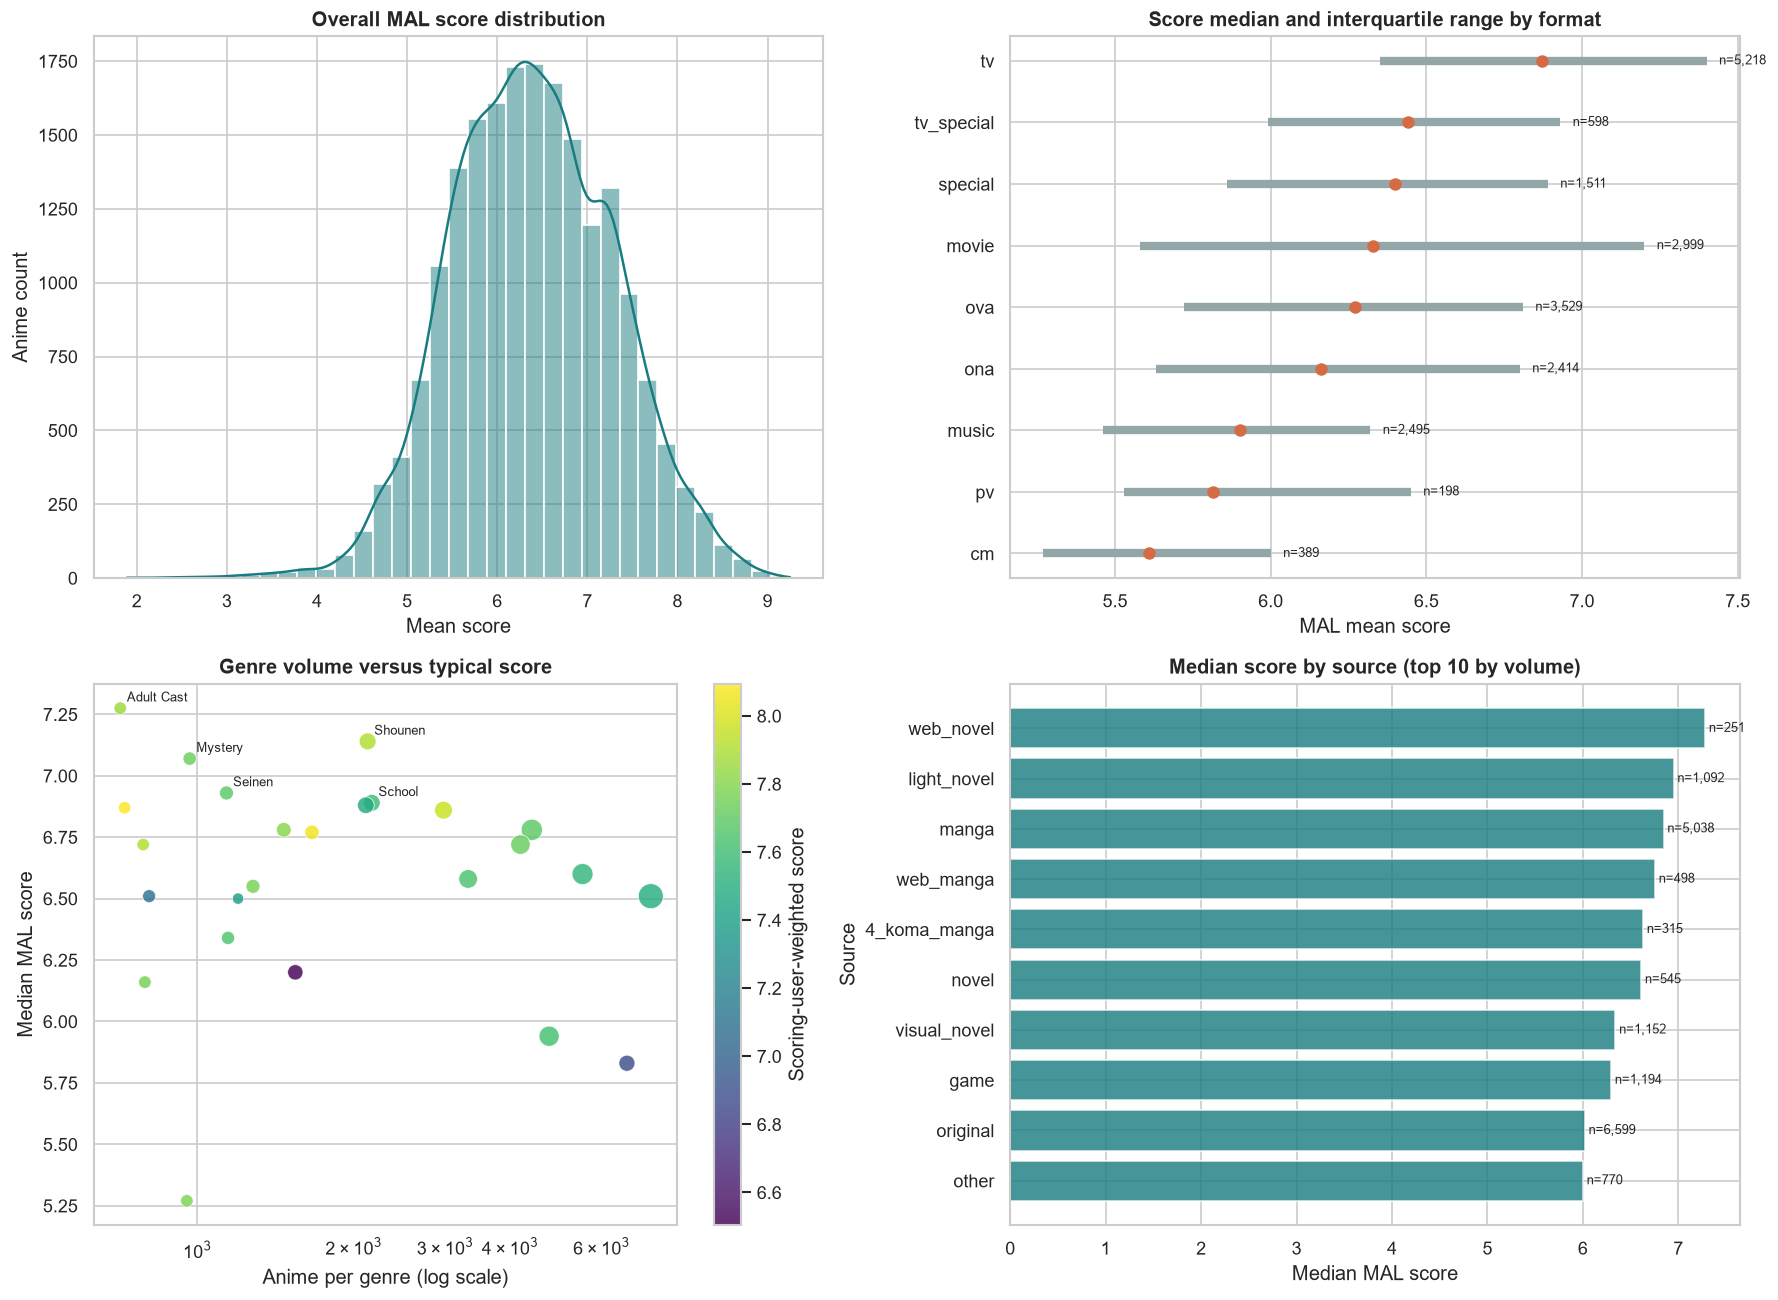

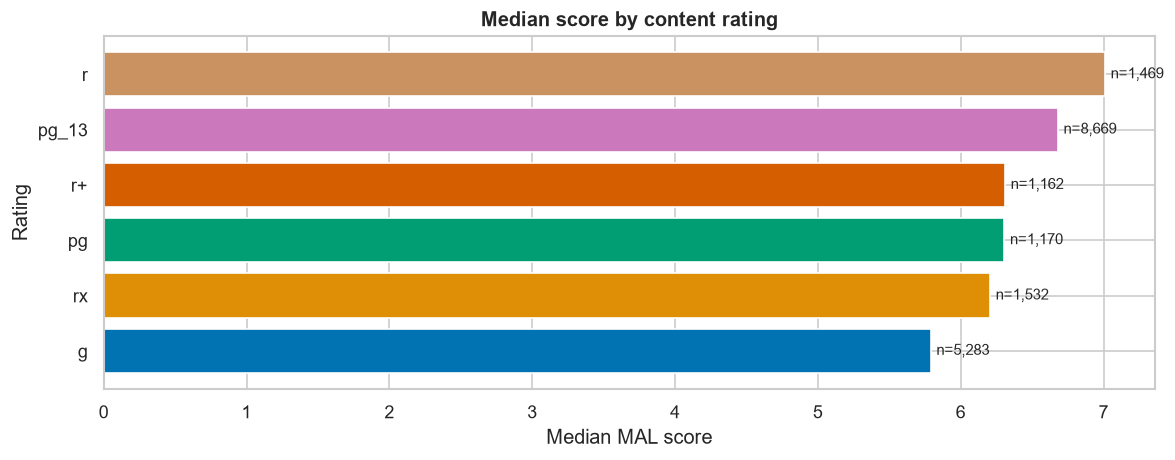

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.histplot(data=queries.score_distribution(engine), x='mean_score', bins=35, kde=True,
             color='#187c80', ax=axes[0, 0])
axes[0, 0].set(title='Overall MAL score distribution', xlabel='Mean score', ylabel='Anime count')

format_plot = df_formats.sort_values('median_score')
for position, (_, row) in enumerate(format_plot.iterrows()):
    axes[0, 1].hlines(position, row['q1_score'], row['q3_score'], color='#93a7a8', linewidth=5)
    axes[0, 1].scatter(row['median_score'], position, color='#d56b45', s=42, zorder=3)
    axes[0, 1].text(row['q3_score'] + 0.04, position, f"n={int(row['scored_count']):,}", va='center', fontsize=8)
axes[0, 1].set_yticks(range(len(format_plot)), format_plot['media_type'])
axes[0, 1].set(title='Score median and interquartile range by format', xlabel='MAL mean score', ylabel='')

volume_genres = df_genres.nlargest(25, 'anime_count').copy()
point_sizes = 35 + 190 * volume_genres['scored_count'] / volume_genres['scored_count'].max()
points = axes[1, 0].scatter(volume_genres['anime_count'], volume_genres['median_score'],
                            s=point_sizes, c=volume_genres['weighted_score'], cmap='viridis',
                            alpha=0.82, edgecolor='white', linewidth=0.5)
axes[1, 0].set_xscale('log')
axes[1, 0].set(title='Genre volume versus typical score', xlabel='Anime per genre (log scale)', ylabel='Median MAL score')
fig.colorbar(points, ax=axes[1, 0], label='Scoring-user-weighted score')
for _, row in volume_genres.nlargest(5, 'median_score').iterrows():
    axes[1, 0].annotate(row['genre'], (row['anime_count'], row['median_score']), xytext=(4, 4),
                        textcoords='offset points', fontsize=8)

category_points = sns.color_palette('colorblind', n_colors=len(df_sources))
source_plot = df_sources.nlargest(10, 'anime_count').sort_values('median_score')
axes[1, 1].barh(source_plot['source'], source_plot['median_score'], color='#187c80', alpha=0.8)
axes[1, 1].set(title='Median score by source (top 10 by volume)', xlabel='Median MAL score', ylabel='Source')
for position, (_, row) in enumerate(source_plot.iterrows()):
    axes[1, 1].text(row['median_score'] + 0.04, position, f"n={int(row['scored_count']):,}", va='center', fontsize=8)

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
rating_plot = df_ratings.sort_values('median_score')
ax.barh(rating_plot['rating'], rating_plot['median_score'], color=sns.color_palette('colorblind', len(rating_plot)))
ax.set(title='Median score by content rating', xlabel='Median MAL score', ylabel='Rating')
for position, (_, row) in enumerate(rating_plot.iterrows()):
    ax.text(row['median_score'] + 0.04, position, f"n={int(row['scored_count']):,}", va='center', fontsize=9)
fig.tight_layout()
plt.show()

## Audience attention and score

The audience scatter uses a deterministic 5,000-title sample so dense regions stay legible. MAL list-user counts are highly skewed, so the x-axis is logarithmic; rank and popularity remain separate fields.

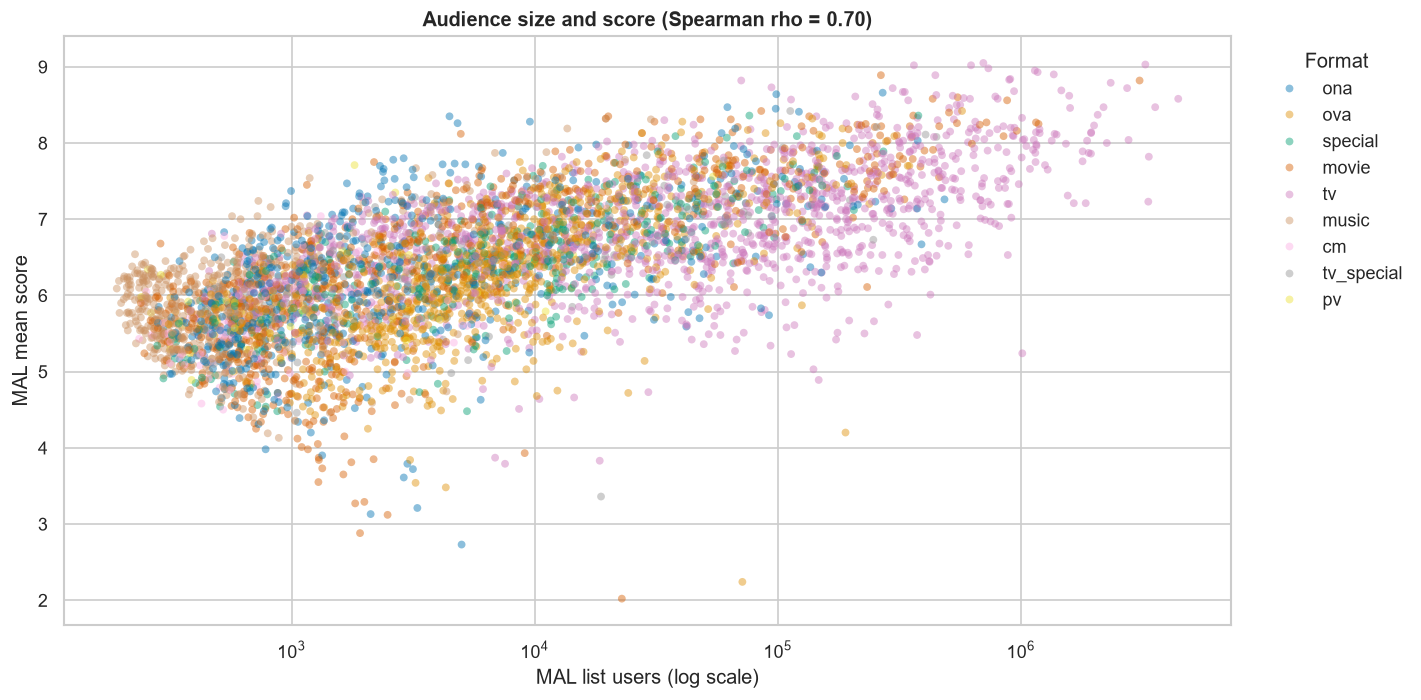

Sample size: 5,000 anime; user count is not a measure of score confidence by itself.


In [11]:
spearman = df_audience[['mean_score', 'num_list_users']].corr(method='spearman').iloc[0, 1]
fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(data=df_audience, x='num_list_users', y='mean_score', hue='media_type',
                alpha=0.45, s=22, linewidth=0, palette='colorblind', ax=ax)
ax.set_xscale('log')
ax.set(title=f'Audience size and score (Spearman rho = {spearman:.2f})',
       xlabel='MAL list users (log scale)', ylabel='MAL mean score')
ax.legend(title='Format', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
fig.tight_layout()
plt.show()
print(f"Sample size: {len(df_audience):,} anime; user count is not a measure of score confidence by itself.")

## Studios, episode bands, and ranked titles

Studio credits can overlap, so each studio count is distinct within that studio and the same anime may appear under multiple studios. Episode-length comparisons are stratified by format and omit unknown or zero episode counts.

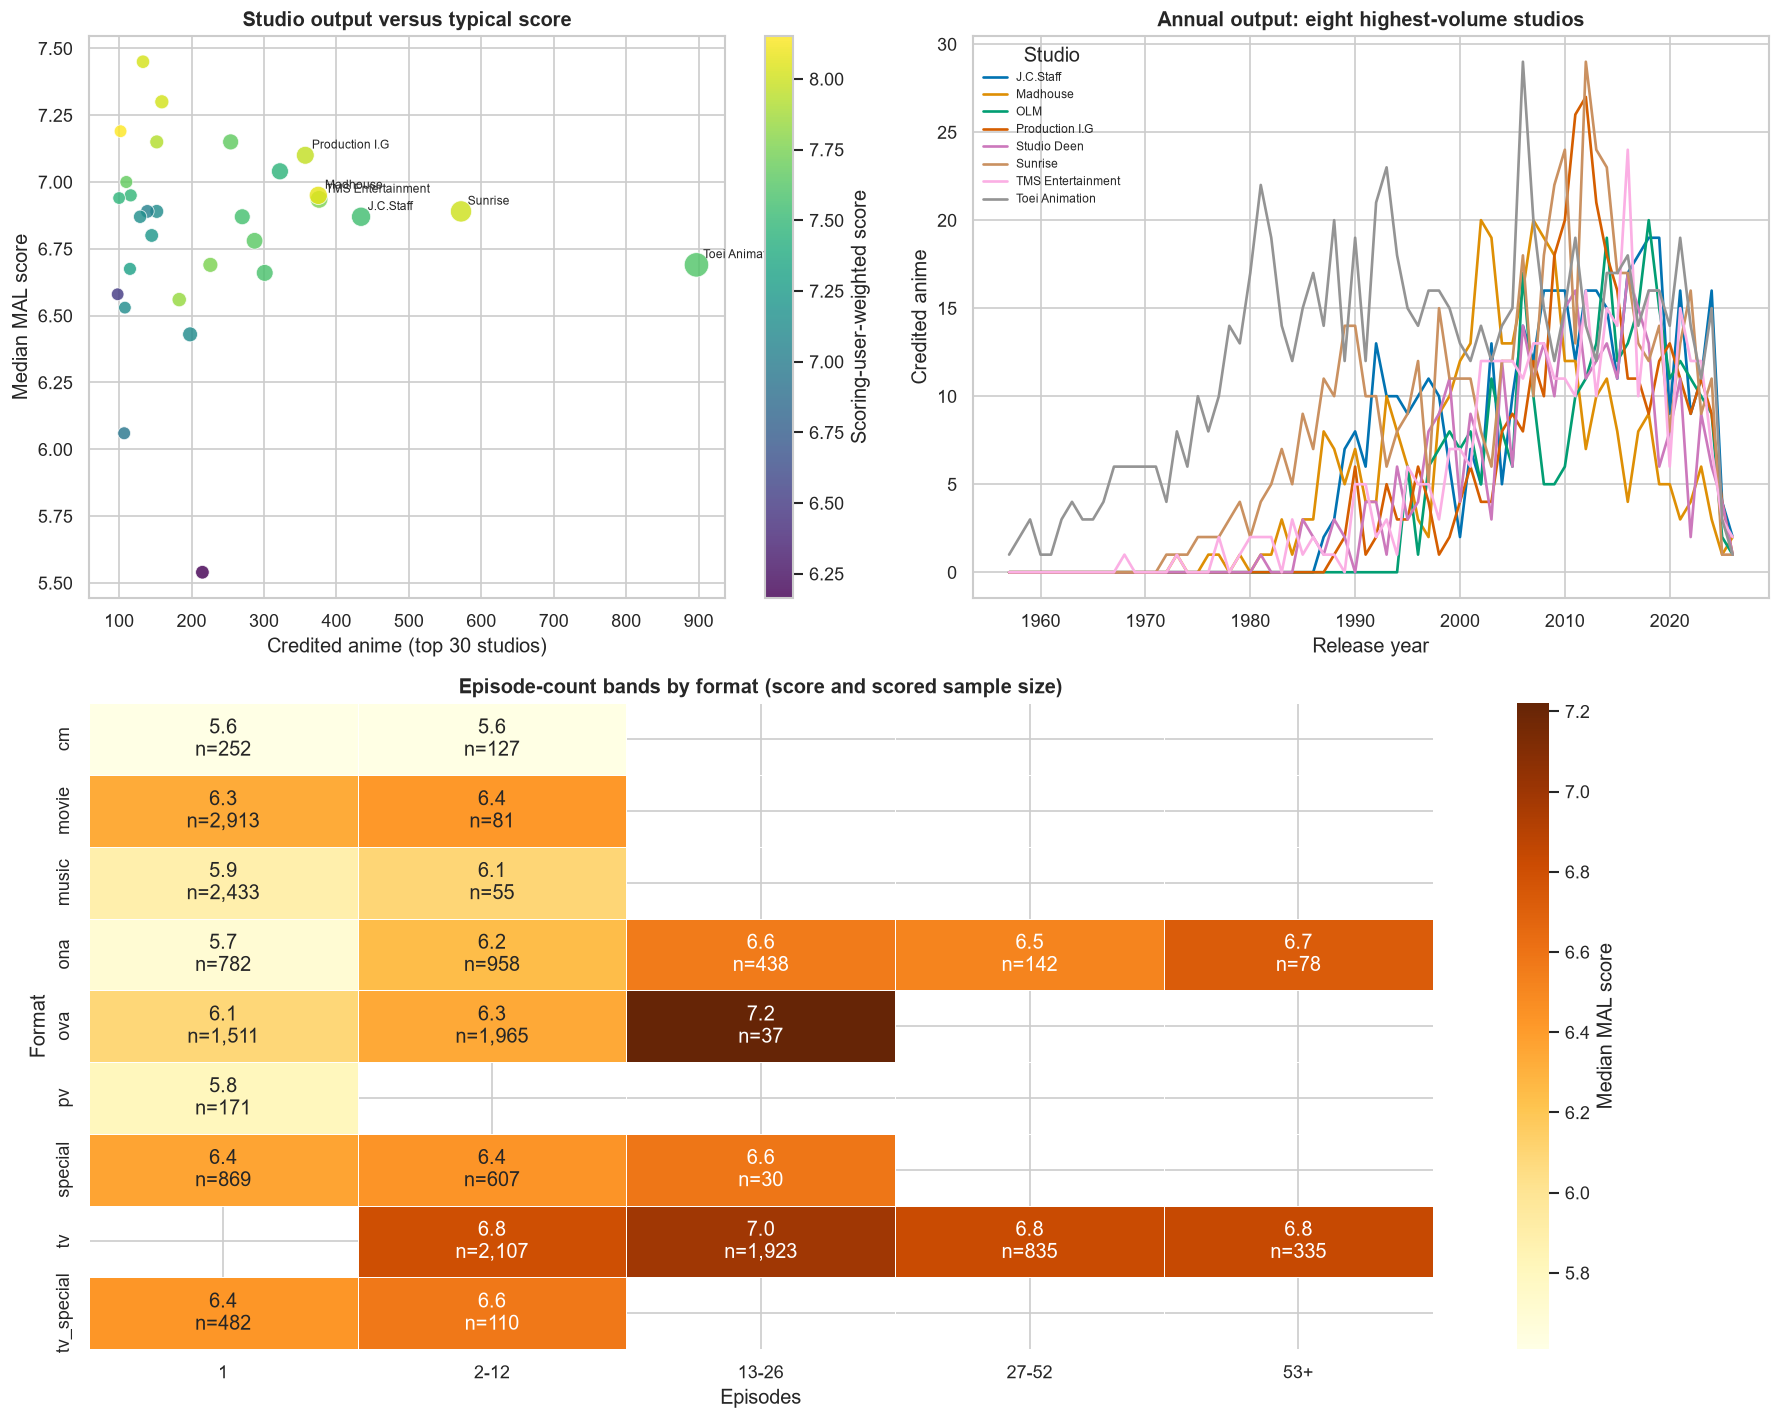

In [12]:
fig = plt.figure(figsize=(15, 12))
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.15])
ax1 = fig.add_subplot(grid[0, 0])
ax2 = fig.add_subplot(grid[0, 1])
ax3 = fig.add_subplot(grid[1, :])

studio_plot = df_studios.nlargest(30, 'anime_count').copy()
studio_sizes = 35 + 180 * studio_plot['scored_count'] / studio_plot['scored_count'].max()
studio_points = ax1.scatter(studio_plot['anime_count'], studio_plot['median_score'],
                            s=studio_sizes, c=studio_plot['weighted_score'], cmap='viridis',
                            alpha=0.82, edgecolor='white', linewidth=0.5)
ax1.set(title='Studio output versus typical score', xlabel='Credited anime (top 30 studios)', ylabel='Median MAL score')
fig.colorbar(studio_points, ax=ax1, label='Scoring-user-weighted score')
for _, row in studio_plot.nlargest(6, 'anime_count').iterrows():
    ax1.annotate(row['studio'], (row['anime_count'], row['median_score']), xytext=(4, 4),
                 textcoords='offset points', fontsize=7)

studio_totals = df_studio_year.groupby('studio')['anime_count'].sum().nlargest(8).index
studio_trend = (
    df_studio_year[df_studio_year['studio'].isin(studio_totals)]
    .pivot(index='year', columns='studio', values='anime_count')
    .fillna(0)
    .sort_index()
)
studio_trend.plot(ax=ax2, linewidth=1.6)
ax2.set(title='Annual output: eight highest-volume studios', xlabel='Release year', ylabel='Credited anime')
ax2.xaxis.set_major_locator(plt.MaxNLocator(8))
ax2.legend(title='Studio', fontsize=7, frameon=False, loc='upper left')

episode_order = ['1', '2-12', '13-26', '27-52', '53+']
episode_scores = df_episodes.pivot(index='media_type', columns='episode_band', values='median_score').reindex(columns=episode_order)
episode_labels = df_episodes.assign(
    label=df_episodes.apply(lambda row: f"{row['median_score']:.1f}\nn={int(row['scored_count']):,}", axis=1)
).pivot(index='media_type', columns='episode_band', values='label').reindex(columns=episode_order)
sns.heatmap(episode_scores, annot=episode_labels, fmt='', cmap='YlOrBr', linewidths=0.4,
            cbar_kws={'label': 'Median MAL score'}, ax=ax3)
ax3.set(title='Episode-count bands by format (score and scored sample size)', xlabel='Episodes', ylabel='Format')
fig.tight_layout()
plt.show()

## Highest-ranked titles

The table filters out entries with fewer than 1,000 scoring users and shows MAL rank, popularity, mean score, and vote count as separate measures.

In [13]:
rank_table = df_top.rename(columns={
    'title': 'Title',
    'media_type': 'Format',
    'mean_score': 'Mean score',
    'rank': 'MAL rank',
    'popularity': 'Popularity rank',
    'num_scoring_users': 'Scoring users',
})
display(
    rank_table.style
    .format({'Mean score': '{:.2f}', 'MAL rank': '{:,.0f}', 'Popularity rank': '{:,.0f}', 'Scoring users': '{:,.0f}'})
    .background_gradient(subset=['Mean score'], cmap='YlGnBu')
    .hide(axis='index')
)

Title,Format,Mean score,MAL rank,Popularity rank,Scoring users
Sousou no Frieren,tv,9.25,1,97,"939,074"
Fullmetal Alchemist: Brotherhood,tv,9.11,2,3,"2,343,888"
Steins;Gate,tv,9.07,5,14,"1,541,632"
Chainsaw Man Movie: Reze-hen,movie,9.05,6,465,"362,978"
Gintama: The Final,movie,9.05,7,"1,503","89,201"
Gintama°,tv,9.05,8,350,"275,626"
Shingeki no Kyojin Season 3 Part 2,tv,9.05,9,20,"1,826,855"
Hunter x Hunter (2011),tv,9.03,11,8,"2,014,538"
Ginga Eiyuu Densetsu,ova,9.02,12,756,"89,461"
Gintama',tv,9.02,13,407,"260,971"
